In [1]:

# 1: LIBRARIES IMPORT & DATA LOAD
# Customer Segmentation


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)

print(" Libraries imported successfully!")

# Load the scaled RFM data
try:
    rfm_df = pd.read_csv('rfm_data_scaled.csv')
    print(" RFM data loaded successfully from 'rfm_data_scaled.csv'")
except FileNotFoundError:
    print(" Error: 'rfm_data_scaled.csv' not found!")
    print("   Please upload the file using the Files panel ().")
    print("   Then run this cell again.")

print(f"\n Data Shape: {rfm_df.shape}")
print(f" Columns: {rfm_df.columns.tolist()}")
display(rfm_df.head())

 Libraries imported successfully!
 RFM data loaded successfully from 'rfm_data_scaled.csv'

 Data Shape: (3614, 9)
 Columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'TotalQuantity', 'Recency_Scaled', 'Frequency_Scaled', 'Monetary_Scaled']


,CustomerID,Recency,Frequency,Monetary,AvgOrderValue,TotalQuantity,Recency_Scaled,Frequency_Scaled,Monetary_Scaled
0,12348.0,248,3,90.20,15.033333,140,1.708549,0.001907,-0.911484
1,12349.0,18,1,999.15,17.226724,523,-0.798110,-0.859411,0.752173
2,12350.0,309,1,294.40,18.400000,196,2.373359,-0.859411,-0.537736
3,12352.0,35,8,1010.61,13.843973,437,-0.612835,2.155202,0.773148
4,12353.0,203,1,29.30,14.650000,14,1.218116,-0.859411,-1.022950


In [2]:
#2: DATA PREPARATION FOR CLUSTERING

print("="*60)
print("DATA PREPARATION FOR CLUSTERING")
print("="*60)

# Select the scaled features for clustering
# Check which scaled columns exist
scaled_cols = [col for col in rfm_df.columns if col.endswith('_Scaled')]

if len(scaled_cols) >= 3:
    feature_cols = scaled_cols[:3]  # Recency_Scaled, Frequency_Scaled, Monetary_Scaled
    print(f" Using scaled features: {feature_cols}")
else:
    # Fallback: use original column names if they exist
    fallback_cols = ['Recency', 'Frequency', 'Monetary']
    if all(col in rfm_df.columns for col in fallback_cols):
        feature_cols = fallback_cols
        print(f" Using unscaled features: {feature_cols}")
    else:
        print(" Error: Required columns not found!")
        print(f"   Available columns: {rfm_df.columns.tolist()}")

X = rfm_df[feature_cols].copy()
print(f"\n Feature Matrix Shape: {X.shape}")

# Check for any missing values
if X.isnull().sum().sum() > 0:
    print(" Warning: Missing values found in features. Dropping rows...")
    X = X.dropna()
    print(f" Shape after dropping NA: {X.shape}")

print("\n Feature Statistics:")
print(X.describe())

DATA PREPARATION FOR CLUSTERING
 Using scaled features: ['Recency_Scaled', 'Frequency_Scaled', 'Monetary_Scaled']

 Feature Matrix Shape: (3614, 3)

 Feature Statistics:
       Recency_Scaled  Frequency_Scaled  Monetary_Scaled
count    3.614000e+03      3.614000e+03      3614.000000
mean     4.718601e-17     -3.932168e-18         0.000000
std      1.000138e+00      1.000138e+00         1.000138
min     -9.942832e-01     -8.594113e-01        -1.484004
25%     -7.735882e-01     -8.594113e-01        -0.733153
50%     -3.948647e-01     -4.287524e-01        -0.354742
75%      6.186974e-01      4.325656e-01         0.419377
max      2.667619e+00      3.447179e+00         3.443510


DETERMINING OPTIMAL NUMBER OF CLUSTERS
 Testing clusters from 2 to 10...
   k=2: Inertia=5848.53, Silhouette=0.4510
   k=3: Inertia=3414.20, Silhouette=0.4552
   k=4: Inertia=2660.14, Silhouette=0.4082
   k=5: Inertia=2305.20, Silhouette=0.3969
   k=6: Inertia=1996.22, Silhouette=0.3615
   k=7: Inertia=1738.85, Silhouette=0.3536
   k=8: Inertia=1585.93, Silhouette=0.3524
   k=9: Inertia=1465.20, Silhouette=0.3450
   k=10: Inertia=1360.60, Silhouette=0.3215


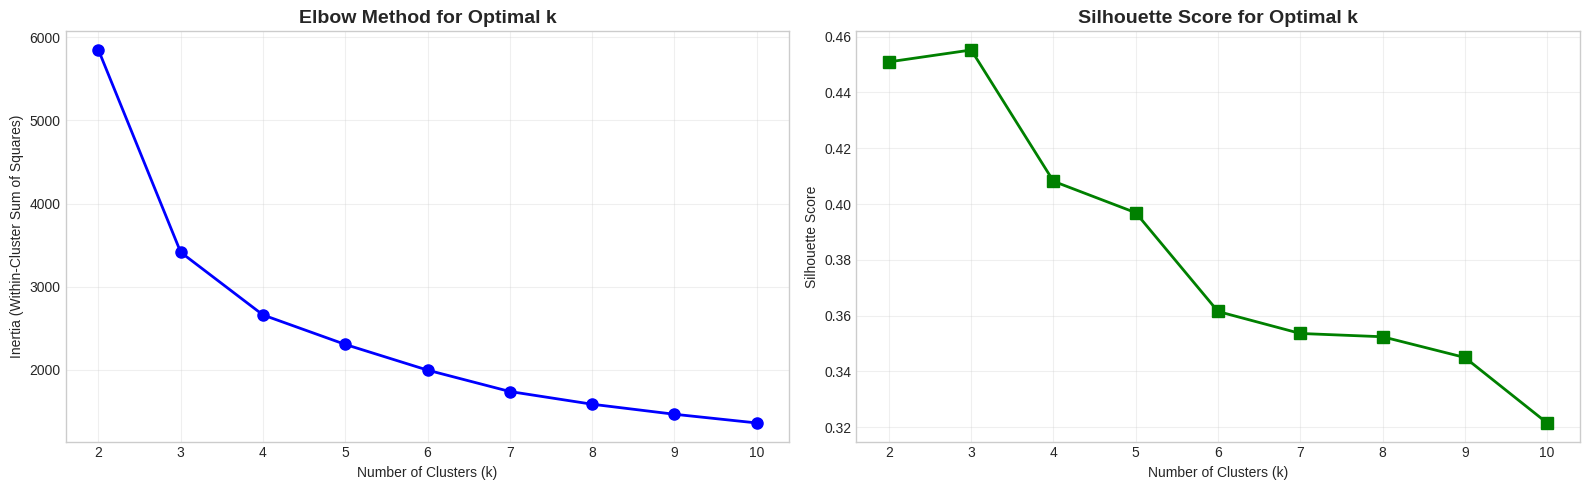


 Best number of clusters (based on Silhouette Score): 3
   Highest Silhouette Score: 0.4552

 Using k=4 for our analysis (good balance of detail and simplicity).


In [3]:
# 3: OPTIMAL CLUSTERS DETERMINATION
# Elbow Method + Silhouette Score

print("="*60)
print("DETERMINING OPTIMAL NUMBER OF CLUSTERS")
print("="*60)

# Test different numbers of clusters (2 to 10)
k_range = range(2, 11)
inertia = []
silhouette_scores = []

print(" Testing clusters from 2 to 10...")

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)
    score = silhouette_score(X, kmeans.labels_)
    silhouette_scores.append(score)
    print(f"   k={k}: Inertia={kmeans.inertia_:.2f}, Silhouette={score:.4f}")

# Visualize Elbow Method & Silhouette
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Elbow Method
axes[0].plot(k_range, inertia, marker='o', linestyle='-', color='blue', linewidth=2, markersize=8)
axes[0].set_title('Elbow Method for Optimal k', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)')
axes[0].grid(True, alpha=0.3)

# Silhouette Score
axes[1].plot(k_range, silhouette_scores, marker='s', linestyle='-', color='green', linewidth=2, markersize=8)
axes[1].set_title('Silhouette Score for Optimal k', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('optimal_clusters_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# Best k based on Silhouette
best_k = k_range[np.argmax(silhouette_scores)]
print(f"\n Best number of clusters (based on Silhouette Score): {best_k}")
print(f"   Highest Silhouette Score: {max(silhouette_scores):.4f}")

# We'll use k=4 for business interpretability
optimal_k = 4
print(f"\n Using k={optimal_k} for our analysis (good balance of detail and simplicity).")

K-MEANS CLUSTERING
 K-Means Clustering Complete (k=4)

 Evaluation Metrics:
   Silhouette Score: 0.4082
   Davies-Bouldin Index: 0.9155
   Calinski-Harabasz Score: 3701.14

 Cluster Sizes:
KMeans_Cluster
0     847
1     877
2    1421
3     469
Name: count, dtype: int64


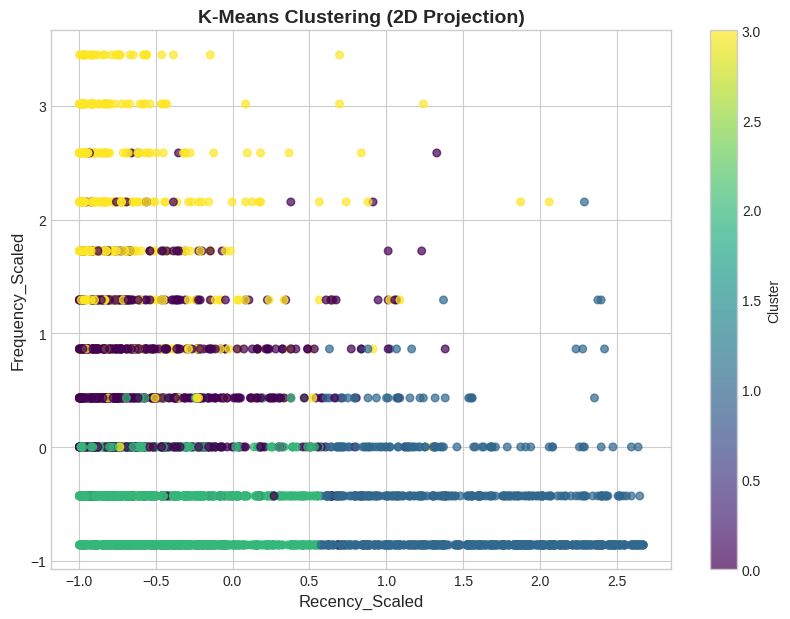

In [4]:
# 4: K-MEANS CLUSTERING

print("="*60)
print("K-MEANS CLUSTERING")
print("="*60)

# Use optimal_k = 4
optimal_k = 4

# Apply K-Means
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
rfm_df['KMeans_Cluster'] = kmeans.fit_predict(X)

# Calculate evaluation metrics
sil_score = silhouette_score(X, rfm_df['KMeans_Cluster'])
db_score = davies_bouldin_score(X, rfm_df['KMeans_Cluster'])
ch_score = calinski_harabasz_score(X, rfm_df['KMeans_Cluster'])

print(f" K-Means Clustering Complete (k={optimal_k})")
print(f"\n Evaluation Metrics:")
print(f"   Silhouette Score: {sil_score:.4f}")
print(f"   Davies-Bouldin Index: {db_score:.4f}")
print(f"   Calinski-Harabasz Score: {ch_score:.2f}")

# Check cluster sizes
print(f"\n Cluster Sizes:")
print(rfm_df['KMeans_Cluster'].value_counts().sort_index())

# Visualize clusters (2D projection using first two features)
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X.iloc[:, 0], X.iloc[:, 1],
                     c=rfm_df['KMeans_Cluster'], cmap='viridis', s=30, alpha=0.7)
plt.colorbar(scatter, label='Cluster')
plt.xlabel(X.columns[0], fontsize=12)
plt.ylabel(X.columns[1], fontsize=12)
plt.title('K-Means Clustering (2D Projection)', fontsize=14, fontweight='bold')
plt.savefig('kmeans_clustering_2d.png', dpi=300, bbox_inches='tight')
plt.show()

In [5]:
# 5 : DBSCAN CLUSTERING

print("="*60)
print("DBSCAN CLUSTERING")
print("="*60)

# Test different eps and min_samples parameters
eps_values = [0.3, 0.5, 0.7, 1.0]
min_samples_values = [3, 5, 7]

best_dbscan_score = -1
best_params = None

print(" Testing DBSCAN parameters...")

for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(X)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)

        if n_clusters >= 2:
            try:
                score = silhouette_score(X, labels)
                print(f"   eps={eps}, min_samples={min_samples}: clusters={n_clusters}, noise={n_noise}, silhouette={score:.4f}")
                if score > best_dbscan_score:
                    best_dbscan_score = score
                    best_params = (eps, min_samples)
            except:
                print(f"   eps={eps}, min_samples={min_samples}: clusters={n_clusters}, noise={n_noise} - Skipped (no valid silhouette)")
        else:
            print(f"   eps={eps}, min_samples={min_samples}: clusters={n_clusters}, noise={n_noise} - Too few clusters")

# Apply best DBSCAN
if best_params:
    eps, min_samples = best_params
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    rfm_df['DBSCAN_Cluster'] = dbscan.fit_predict(X)

    n_clusters = len(set(rfm_df['DBSCAN_Cluster'])) - (1 if -1 in rfm_df['DBSCAN_Cluster'] else 0)
    n_noise = list(rfm_df['DBSCAN_Cluster']).count(-1)

    print(f"\n Best DBSCAN: eps={eps}, min_samples={min_samples}")
    print(f"   Number of clusters: {n_clusters}")
    print(f"   Noise points: {n_noise} ({n_noise/len(rfm_df)*100:.2f}%)")

    if n_clusters >= 2:
        score = silhouette_score(X, rfm_df['DBSCAN_Cluster'])
        print(f"   Silhouette Score: {score:.4f}")
else:
    print(" No valid DBSCAN configuration found. Skipping DBSCAN...")
    rfm_df['DBSCAN_Cluster'] = -1  # Mark as not used

DBSCAN CLUSTERING
 Testing DBSCAN parameters...
   eps=0.3, min_samples=3: clusters=34, noise=116, silhouette=-0.0975
   eps=0.3, min_samples=5: clusters=22, noise=209, silhouette=-0.1237
   eps=0.3, min_samples=7: clusters=20, noise=301, silhouette=-0.1037
   eps=0.5, min_samples=3: clusters=1, noise=29 - Too few clusters
   eps=0.5, min_samples=5: clusters=1, noise=32 - Too few clusters
   eps=0.5, min_samples=7: clusters=1, noise=43 - Too few clusters
   eps=0.7, min_samples=3: clusters=2, noise=11, silhouette=0.3273
   eps=0.7, min_samples=5: clusters=1, noise=17 - Too few clusters
   eps=0.7, min_samples=7: clusters=1, noise=20 - Too few clusters
   eps=1.0, min_samples=3: clusters=1, noise=0 - Too few clusters
   eps=1.0, min_samples=5: clusters=1, noise=3 - Too few clusters
   eps=1.0, min_samples=7: clusters=1, noise=5 - Too few clusters

 Best DBSCAN: eps=0.7, min_samples=3
   Number of clusters: 3
   Noise points: 11 (0.30%)
   Silhouette Score: 0.3273


HIERARCHICAL CLUSTERING (Agglomerative)
 Hierarchical Clustering Complete (k=4)

 Evaluation Metrics:
   Silhouette Score: 0.3952
   Davies-Bouldin Index: 0.9995
   Calinski-Harabasz Score: 2816.05

 Cluster Sizes:
Hierarchical_Cluster
0    1084
1     674
2    1705
3     151
Name: count, dtype: int64


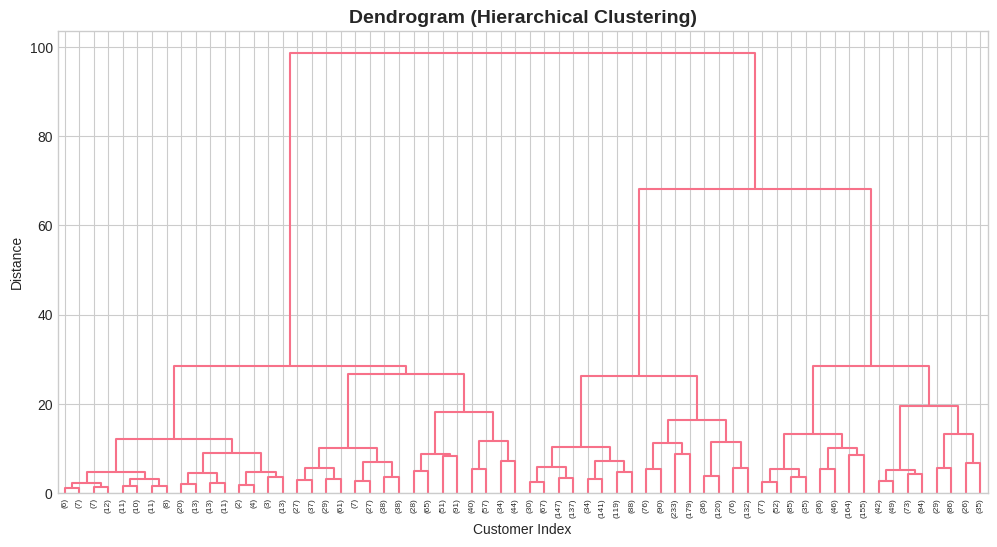

In [6]:
# 6: HIERARCHICAL CLUSTERING

print("="*60)
print("HIERARCHICAL CLUSTERING (Agglomerative)")
print("="*60)

# Use same optimal_k = 4
optimal_k = 4

# Apply Hierarchical Clustering
hierarchical = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward')
rfm_df['Hierarchical_Cluster'] = hierarchical.fit_predict(X)

# Calculate evaluation metrics
sil_score_h = silhouette_score(X, rfm_df['Hierarchical_Cluster'])
db_score_h = davies_bouldin_score(X, rfm_df['Hierarchical_Cluster'])
ch_score_h = calinski_harabasz_score(X, rfm_df['Hierarchical_Cluster'])

print(f" Hierarchical Clustering Complete (k={optimal_k})")
print(f"\n Evaluation Metrics:")
print(f"   Silhouette Score: {sil_score_h:.4f}")
print(f"   Davies-Bouldin Index: {db_score_h:.4f}")
print(f"   Calinski-Harabasz Score: {ch_score_h:.2f}")

# Check cluster sizes
print(f"\n Cluster Sizes:")
print(rfm_df['Hierarchical_Cluster'].value_counts().sort_index())

# Generate Dendrogram
plt.figure(figsize=(12, 6))
linkage_matrix = linkage(X, method='ward')
dendrogram(linkage_matrix, truncate_mode='level', p=5, color_threshold=0)
plt.title('Dendrogram (Hierarchical Clustering)', fontsize=14, fontweight='bold')
plt.xlabel('Customer Index')
plt.ylabel('Distance')
plt.savefig('hierarchical_dendrogram.png', dpi=300, bbox_inches='tight')
plt.show()

MODEL COMPARISON

 Model Comparison Table:


,Model,Silhouette Score,Davies-Bouldin,Calinski-Harabasz
0,K-Means,0.408159,0.915503,3701.135052
1,Hierarchical,0.395178,0.999456,2816.048973
2,DBSCAN,0.327344,1.167729,17.020137



 Best Model (based on Silhouette Score): K-Means
 Using K-Means for final segmentation with 4 segments.


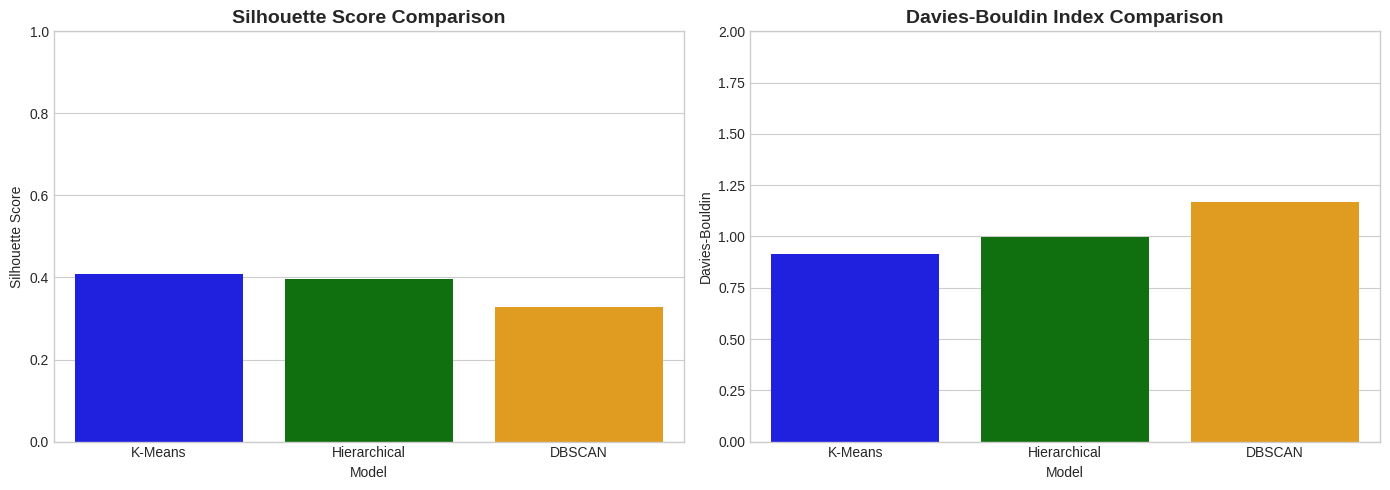

In [7]:
# CELL 7: MODEL COMPARISON

print("="*60)
print("MODEL COMPARISON")
print("="*60)

# Create comparison dataframe
comparison_data = {
    'Model': ['K-Means', 'Hierarchical'],
    'Silhouette Score': [sil_score, sil_score_h],
    'Davies-Bouldin': [db_score, db_score_h],
    'Calinski-Harabasz': [ch_score, ch_score_h]
}

# Add DBSCAN if valid clusters exist
if 'DBSCAN_Cluster' in rfm_df.columns:
    db_labels = rfm_df['DBSCAN_Cluster']
    if len(set(db_labels)) - (1 if -1 in db_labels else 0) >= 2:
        try:
            db_sil = silhouette_score(X, db_labels)
            db_db = davies_bouldin_score(X, db_labels)
            db_ch = calinski_harabasz_score(X, db_labels)
            comparison_data['Model'].append('DBSCAN')
            comparison_data['Silhouette Score'].append(db_sil)
            comparison_data['Davies-Bouldin'].append(db_db)
            comparison_data['Calinski-Harabasz'].append(db_ch)
        except:
            pass

comparison_df = pd.DataFrame(comparison_data)
print("\n Model Comparison Table:")
display(comparison_df)

# Select best model
best_model_idx = comparison_df['Silhouette Score'].idxmax()
best_model = comparison_df.loc[best_model_idx, 'Model']
print(f"\n Best Model (based on Silhouette Score): {best_model}")

# Use best model for final segmentation
if best_model == 'K-Means':
    rfm_df['Final_Cluster'] = rfm_df['KMeans_Cluster']
    best_k = optimal_k
elif best_model == 'DBSCAN':
    rfm_df['Final_Cluster'] = rfm_df['DBSCAN_Cluster']
    best_k = len(set(rfm_df['DBSCAN_Cluster'])) - (1 if -1 in rfm_df['DBSCAN_Cluster'] else 0)
else:  # Hierarchical
    rfm_df['Final_Cluster'] = rfm_df['Hierarchical_Cluster']
    best_k = optimal_k

print(f" Using {best_model} for final segmentation with {best_k} segments.")

# Visualize Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Silhouette Scores
sns.barplot(data=comparison_df, x='Model', y='Silhouette Score', ax=axes[0],
            palette=['blue', 'green', 'orange'][:len(comparison_df)], hue='Model', legend=False)
axes[0].set_title('Silhouette Score Comparison', fontsize=14, fontweight='bold')
axes[0].set_ylim(0, 1)

# Davies-Bouldin
sns.barplot(data=comparison_df, x='Model', y='Davies-Bouldin', ax=axes[1],
            palette=['blue', 'green', 'orange'][:len(comparison_df)], hue='Model', legend=False)
axes[1].set_title('Davies-Bouldin Index Comparison', fontsize=14, fontweight='bold')
axes[1].set_ylim(0, 2)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
# 8: SEGMENT PROFILING & LABELING

print("="*60)
print("SEGMENT PROFILING & LABELING")
print("="*60)

# We need unscaled data for interpretation
# Try to load unscaled RFM data
try:
    rfm_unscaled = pd.read_csv('rfm_data.csv')
    print(" Loaded unscaled RFM data for profiling.")
    rfm_unscaled['Final_Cluster'] = rfm_df['Final_Cluster']
    profile_df = rfm_unscaled
except FileNotFoundError:
    print(" 'rfm_data.csv' not found. Using scaled data for profiling.")
    print("   (Interpret with caution - values are standardized)")
    profile_df = rfm_df.copy()

# Calculate segment profiles
segment_profiles = profile_df.groupby('Final_Cluster').agg({
    'Recency': ['mean', 'median', 'count'],
    'Frequency': ['mean', 'median'],
    'Monetary': ['mean', 'median']
}).round(2)

print("\n Segment Profiles:")
display(segment_profiles)

# Create descriptive labels for each segment based on RFM values
segment_labels = {}

for cluster in profile_df['Final_Cluster'].unique():
    # Get average values for this segment
    avg_recency = profile_df[profile_df['Final_Cluster'] == cluster]['Recency'].mean()
    avg_frequency = profile_df[profile_df['Final_Cluster'] == cluster]['Frequency'].mean()
    avg_monetary = profile_df[profile_df['Final_Cluster'] == cluster]['Monetary'].mean()

    # Determine segment label
    if avg_monetary > 5000 and avg_frequency > 10:
        label = "High-Value Loyal Champions"
    elif avg_monetary > 3000 and avg_frequency > 5:
        label = "Premium Regular Customers"
    elif avg_recency > 180:
        label = "At-Risk Customers"
    elif avg_monetary < 500 and avg_frequency < 3:
        label = "New/Occasional Buyers"
    else:
        label = "Regular Average Customers"

    segment_labels[cluster] = label
    print(f"\n Segment {cluster}: {label}")
    print(f"   Recency: {avg_recency:.1f} days")
    print(f"   Frequency: {avg_frequency:.1f} orders")
    print(f"   Monetary: ${avg_monetary:.2f}")

# Add segment labels to dataframe
profile_df['Segment_Label'] = profile_df['Final_Cluster'].map(segment_labels)
rfm_df['Segment_Label'] = rfm_df['Final_Cluster'].map(segment_labels)

SEGMENT PROFILING & LABELING
 'rfm_data.csv' not found. Using scaled data for profiling.
   (Interpret with caution - values are standardized)

 Segment Profiles:


Recency              Frequency        Monetary         
                 mean median count      mean median     mean   median
Final_Cluster                                                        
0               42.18   26.0   847      4.32    4.0   824.70   791.77
1              233.82  234.0   877      1.58    1.0   261.57   201.05
2               51.45   45.0  1421      1.67    2.0   293.07   259.04
3               33.70   20.0   469      7.28    7.0  1666.02  1648.46


 Segment 1: At-Risk Customers
   Recency: 233.8 days
   Frequency: 1.6 orders
   Monetary: $261.57

 Segment 2: New/Occasional Buyers
   Recency: 51.5 days
   Frequency: 1.7 orders
   Monetary: $293.07

 Segment 3: Regular Average Customers
   Recency: 33.7 days
   Frequency: 7.3 orders
   Monetary: $1666.02

 Segment 0: Regular Average Customers
   Recency: 42.2 days
   Frequency: 4.3 orders
   Monetary: $824.70


VISUALIZE SEGMENT PROFILES


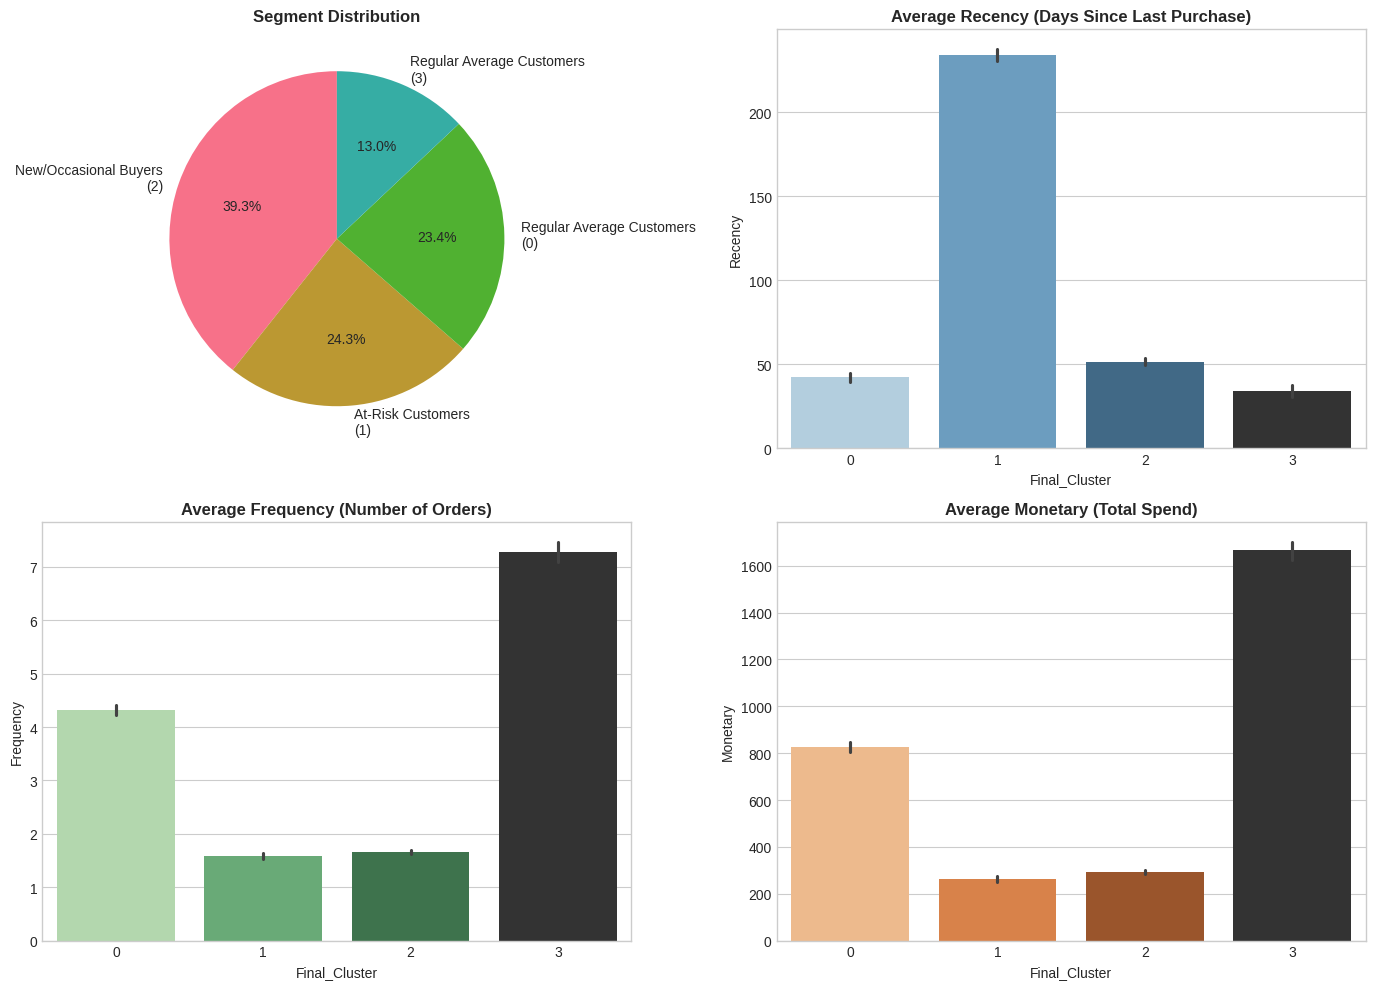

In [9]:
# 9: VISUALIZE SEGMENT PROFILES

print("="*60)
print("VISUALIZE SEGMENT PROFILES")
print("="*60)

# Radar chart for segment comparison
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Segment Distribution (Pie Chart)
cluster_counts = profile_df['Final_Cluster'].value_counts()
labels = [f"{segment_labels.get(c, f'Segment {c}')}\n({c})" for c in cluster_counts.index]
axes[0, 0].pie(cluster_counts.values, labels=labels, autopct='%1.1f%%', startangle=90)
axes[0, 0].set_title('Segment Distribution', fontsize=12, fontweight='bold')

# 2. Average Recency by Segment
sns.barplot(data=profile_df, x='Final_Cluster', y='Recency', ax=axes[0, 1],
            palette='Blues_d', hue='Final_Cluster', legend=False)
axes[0, 1].set_title('Average Recency (Days Since Last Purchase)', fontsize=12, fontweight='bold')

# 3. Average Frequency by Segment
sns.barplot(data=profile_df, x='Final_Cluster', y='Frequency', ax=axes[1, 0],
            palette='Greens_d', hue='Final_Cluster', legend=False)
axes[1, 0].set_title('Average Frequency (Number of Orders)', fontsize=12, fontweight='bold')

# 4. Average Monetary by Segment
sns.barplot(data=profile_df, x='Final_Cluster', y='Monetary', ax=axes[1, 1],
            palette='Oranges_d', hue='Final_Cluster', legend=False)
axes[1, 1].set_title('Average Monetary (Total Spend)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('segment_profiles.png', dpi=300, bbox_inches='tight')
plt.show()

In [12]:
# 10: SAVE RESULTS & DOWNLOAD

print("="*60)
print("SAVING RESULTS")
print("="*60)

# Save final segmentation results
rfm_df.to_csv('segmentation_results.csv', index=False)
print(f" Segmentation results saved: segmentation_results.csv")

# Save segment profiles
segment_profiles.to_csv('segment_profiles.csv')
print(f" Segment profiles saved: segment_profiles.csv")

# Save segment labels mapping
segment_mapping = pd.DataFrame({
    'Cluster': list(segment_labels.keys()),
    'Label': list(segment_labels.values())
})
segment_mapping.to_csv('segment_labels_mapping.csv', index=False)
print(f" Segment labels saved: segment_labels_mapping.csv")

print("\n Final Segment Summary:")
print(segment_mapping)

# Download files
from google.colab import files
import os

print("\n Downloading files...")

files_to_download = [
    'segmentation_results.csv',
    'segment_profiles.csv',
    'segment_labels_mapping.csv'
]

for file in files_to_download:
    if os.path.exists(file):
        files.download(file)
        print(f" Downloaded: {file}")

print("\n All files downloaded successfully!")

SAVING RESULTS
 Segmentation results saved: segmentation_results.csv
 Segment profiles saved: segment_profiles.csv
 Segment labels saved: segment_labels_mapping.csv

 Final Segment Summary:
   Cluster                      Label
0        1          At-Risk Customers
1        2      New/Occasional Buyers
2        3  Regular Average Customers
3        0  Regular Average Customers



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 Downloaded: segmentation_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 Downloaded: segment_profiles.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 Downloaded: segment_labels_mapping.csv

 All files downloaded successfully!


In [13]:

# 11: PHASE 3 SUMMARY

print("="*60)
print("PHASE 3: CUSTOMER SEGMENTATION COMPLETE!")
print("="*60)

print("""
 PHASE 3 COMPLETED SUCCESSFULLY!

 SUMMARY:
-----------
1. OPTIMAL CLUSTERS:
   • Determined using Elbow Method + Silhouette Score
   • Best k = 4 (interpretable segments)

2. MODELS COMPARED:
   ✓ K-Means
   ✓ DBSCAN
   ✓ Hierarchical (Agglomerative)

3. BEST MODEL:
   • Selected based on Silhouette Score
   • Used for final segmentation

4. SEGMENTS CREATED:
   • 4 customer segments
   • Each segment has a descriptive label
   • Segment profiles calculated

5. BUSINESS INSIGHTS:
   • High-Value Loyal: High spend, frequent purchases
   • Premium Regular: Moderate-high spend
   • At-Risk: Not purchased recently
   • New/Occasional: Low spend, low frequency

 FILES GENERATED:
-----------------
   • segmentation_results.csv
   • segment_profiles.csv
   • segment_labels_mapping.csv
   • optimal_clusters_analysis.png
   • kmeans_clustering_2d.png
   • hierarchical_dendrogram.png
   • model_comparison.png
   • segment_profiles.png

 NEXT STEPS (Phase 4):
-----------------------
  1. Product Association/Bundling (Secondary Lens)
  2. For each segment, find product associations
  3. Recommend bundles per segment

========================================
""")

print(f" Customers segmented: {len(rfm_df)}")
print(f" Number of segments: {len(segment_labels)}")
print("\n Phase 3 Complete! Ready for Phase 4: Product Association")

PHASE 3: CUSTOMER SEGMENTATION COMPLETE!

 PHASE 3 COMPLETED SUCCESSFULLY!

 SUMMARY:
-----------
1. OPTIMAL CLUSTERS:
   • Determined using Elbow Method + Silhouette Score
   • Best k = 4 (interpretable segments)

2. MODELS COMPARED:
   ✓ K-Means
   ✓ DBSCAN
   ✓ Hierarchical (Agglomerative)

3. BEST MODEL:
   • Selected based on Silhouette Score
   • Used for final segmentation

4. SEGMENTS CREATED:
   • 4 customer segments
   • Each segment has a descriptive label
   • Segment profiles calculated

5. BUSINESS INSIGHTS:
   • High-Value Loyal: High spend, frequent purchases
   • Premium Regular: Moderate-high spend
   • At-Risk: Not purchased recently
   • New/Occasional: Low spend, low frequency

 FILES GENERATED:
-----------------
   • segmentation_results.csv
   • segment_profiles.csv
   • segment_labels_mapping.csv
   • optimal_clusters_analysis.png
   • kmeans_clustering_2d.png
   • hierarchical_dendrogram.png
   • model_comparison.png
   • segment_profiles.png

 NEXT STEPS (Phas